## When does the normal approximation become useful?

- Let us investigate how the sampling distribution of the sample mean changes
    with sample size when the observations follow a Bernoulli distribution
    with a small success probability.

- central question: How large must the sample size be before the sampling distribution of the sample mean can be approximated reasonably well by a normal distribution?

### Step - 1: Define the population
- Suppose we observe whether an event occurs, where the probability of success is only \(5\%\).
- Let
  $\begin{equation*}
    X_i\sim\operatorname{Bernoulli}(p),\qquad p=0.05.
  \end{equation*}$
- $\begin{equation*}
X_i=
\begin{cases}
1,&\text{with probability }0.05,\\
0,&\text{with probability }0.95.
\end{cases}
\end{equation*}$
- The population mean and variance are
$\begin{equation*}
\mu=p=0.05,\qquad
\sigma^2=p(1-p)=0.0475.
\end{equation*}$

- For a sample of size \(n\), our estimator is the sample mean
$
\begin{equation*}
\overline X_n=\frac{1}{n}\sum_{i=1}^{n}X_i.
\end{equation*}
$

Because the observations are binary, $\overline X_n$ is simply the observed proportion of successes.

### Step - 2: Inspect a single sample

- Before generating thousands of samples, let us examine one dataset.

- go to https://numpy.org/doc/stable/reference/random/generator.html for all the numpy functions associated

In [11]:
import numpy as np
import matplotlib.pyplot as plt

seed = 2026
rng = np.random.default_rng(seed)

p = 0.05
n = 20

X = rng.binomial(1, p, size=n)

print("Observations:", X)
print("Number of successes:", X.sum())
print("Sample mean:", X.mean())
print("Population mean:", p)

Observations: [0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0]
Number of successes: 1
Sample mean: 0.05
Population mean: 0.05


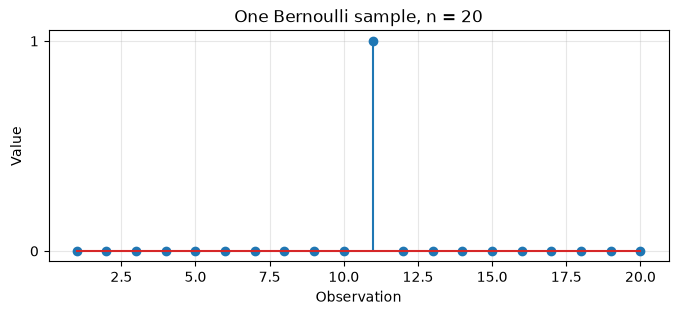

In [12]:
plt.figure(figsize=(8, 3))
plt.stem(np.arange(1, n + 1), X)
plt.xlabel("Observation")
plt.ylabel("Value")
plt.title(f"One Bernoulli sample, n = {n}")
plt.yticks([0, 1])
plt.grid(alpha=0.3)     # Enables grid lin, alpha: Controls the transparency of the grid lines
plt.show()

#### Questions

- How many successes did we observe?
- How does the sample mean compare with the population mean 0.05?
- If we repeated the experiment with another sample of size 20, would you expect the same sample mean?

- this figure shows the observations in a single dataset. 
- It tells us nothing yet about the shape of the sampling distribution.

### Step-3: Generate many sample means

- Now we repeat the sampling experiment $R=10{,}000$ times.
- Each repetition generates a fresh sample of size $n$ and calculates its mean.

In [4]:
R = 10_000
n = 20

X = rng.binomial(1, p, size=(R, n))
sample_means = X.mean(axis=1)

print("Number of simulated datasets:", R)
print("Mean of simulated sample means:", sample_means.mean())
print("Theoretical mean:", p)
print("Empirical standard deviation:", sample_means.std())
print("Theoretical standard error:", np.sqrt(p * (1 - p) / n))

Number of simulated datasets: 10000
Mean of simulated sample means: 0.049554999999999995
Theoretical mean: 0.05
Empirical standard deviation: 0.04829650064963299
Theoretical standard error: 0.04873397172404482


- Plot the sampling distribution.

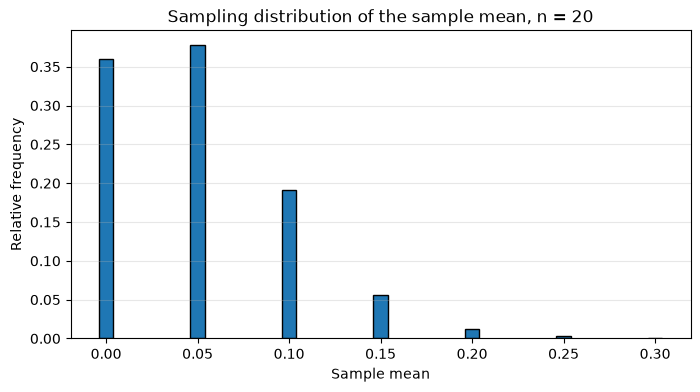

In [5]:
plt.figure(figsize=(8, 4))

values, counts = np.unique(sample_means, return_counts=True)
plt.bar(values, counts / R, width=0.008, edgecolor="black")

plt.xlabel("Sample mean")
plt.ylabel("Relative frequency")
plt.title(f"Sampling distribution of the sample mean, n = {n}")
plt.grid(axis="y", alpha=0.3)
plt.show()

#### Interpretation 

The sample mean can only take values of the form 

$\begin{equation*}
\overline X_n=\frac{k}{n},
\qquad k=0,1,\ldots,n.
\end{equation*}$


- For \(n=20\), the possible values are separated by \(1/20=0.05\).
- Because the probability of success is small, many datasets have zero, one, or only a few successes.
- Consequently, the sampling distribution is discrete and may be strongly asymmetric.


### Step 4 — Increase the sample size

- Let us repeat the experiment for several sample sizes.

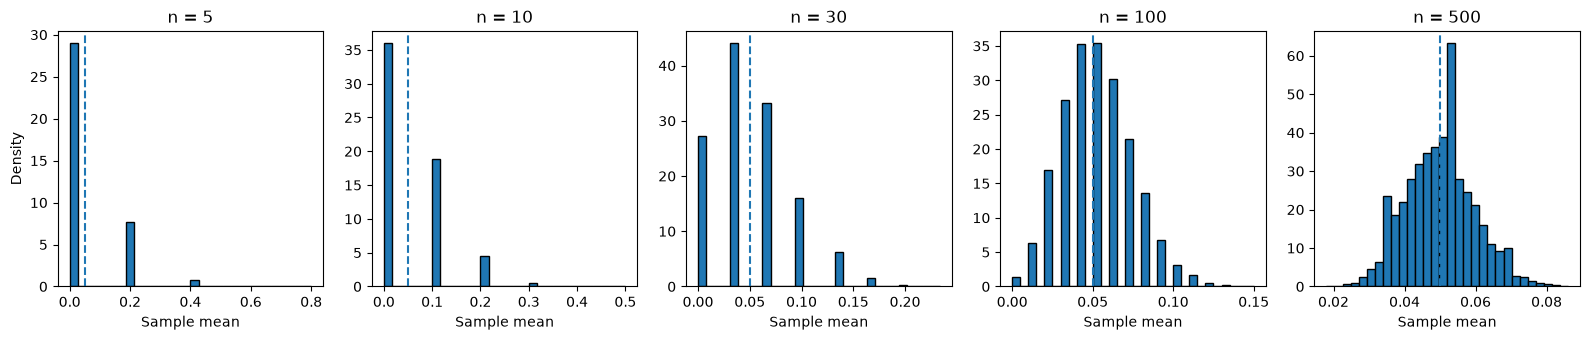

In [14]:
sample_sizes = [5, 10, 30, 100, 500]
R = 10_000

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))

for ax, n in zip(axes, sample_sizes):
    X = rng.binomial(1, p, size=(R, n))
    sample_means = X.mean(axis=1)

    ax.hist(
        sample_means,
        bins=30,
        density=True,
        edgecolor="black"
    )

    ax.axvline(p, linestyle="--")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("Sample mean")

axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()


#### Compare the five histograms.

- As \(n\) increases, the possible sample means become more closely spaced. 
- The sampling distribution also becomes more concentrated around \(p=0.05\).

- However, concentration around the mean and approximation by a normal distribution are different properties.
- A distribution can become more concentrated without becoming well approximated by a normal distribution at every sample size.

### Step 5 — Compare with the normal approximation

The CLT predicts that, for sufficiently large $n$,
\begin{equation*}
\overline X_n
\approx
N\left(p,\frac{p(1-p)}{n}\right).
\end{equation*}

To compare the shapes across different sample sizes, standardize the sample means:
\begin{equation*}
Z_n=
\frac{\overline X_n-p}
{\sqrt{p(1-p)/n}}.
\end{equation*}
Under the normal approximation, $Z_n$ should resemble a standard normal random variable.

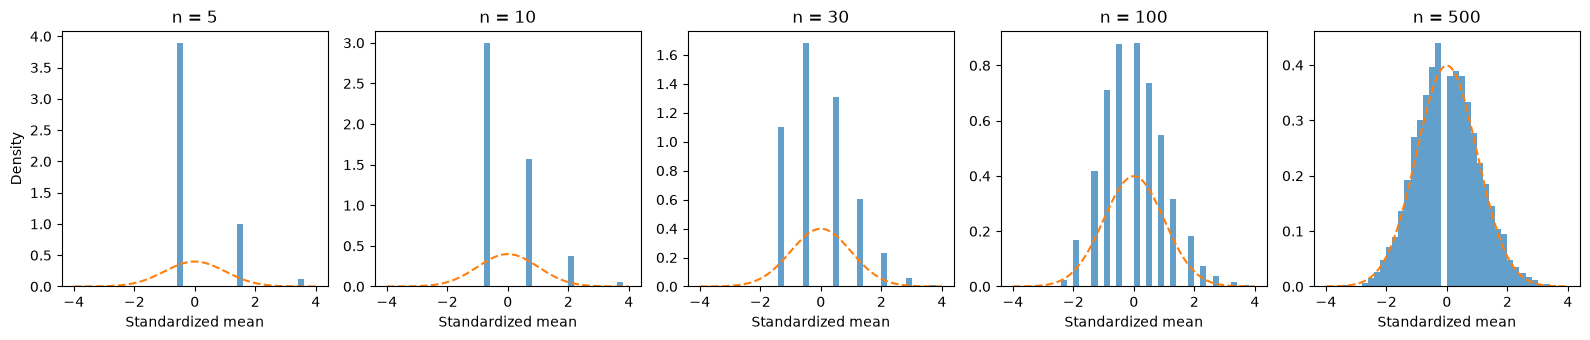

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))

for ax, n in zip(axes, sample_sizes):
    X = rng.binomial(1, p, size=(R, n))
    sample_means = X.mean(axis=1)

    z = (sample_means - p) / np.sqrt(p * (1 - p) / n)

    ax.hist(
        z,
        bins=40,
        range=(-4, 4),
        density=True,
        alpha=0.7
    )

    x = np.linspace(-4, 4, 300)
    pdf = (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * x**2)
    ax.plot(x, pdf, linestyle="--")

    ax.set_title(f"n = {n}")
    ax.set_xlabel("Standardized mean")

axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

- The dashed curve is the standard normal density.